# Random Forest — Hyperparameter Tuning (5-Fold CV, Random Search)

## Overview

Find the best Random Forest configuration for predicting `weighted_rating`, using **5-fold cross-validation on your existing training split**, and report how the tuned model performs on the untouched test split.

## The data

| Split | Rows | Used for |
|---|---:|---|
| Train | 53,574 | All 5 CV folds, then the final refit |
| Test | 13,394 | Reporting only, never used to choose a parameter |

These are the same files the main baseline notebook used (`data/processed/`). Nothing is re-split and no rows are dropped.

## Why random search, not Bayesian or grid

**Random search, and here it is the clearly right choice.** Random Forest has a comparatively flat response surface: most reasonable combinations of `max_features`, `min_samples_leaf` and depth land within a few thousandths of each other. There is very little structure for a surrogate model to learn, so a Bayesian sampler's extra machinery buys almost nothing, while plain random search stays cheap, reproducible and dependency-free. Grid search remains pointless at five parameters, and coarse-to-fine is unnecessary when the surface is this flat.

## What gets searched

| Parameter | Range | Why |
|---|---|---|
| `n_estimators` | 200 – 900 (step 100) | Number of trees; more trees lower variance but cost time |
| `max_depth` | 8 – 40 | Tree depth cap |
| `min_samples_split` | 2 – 20 | Minimum rows required to split a node |
| `min_samples_leaf` | 1 – 20 | Minimum rows per leaf; the main smoothing control |
| `max_features` | 0.10 – 1.00 | Fraction of features offered to each split |

## How long it takes

| Setting | Runtime (approx.) |
|---|---|
| `QUICK = False` | 25–45 minutes |
| `QUICK = True` | 4–6 minutes |

Every trial is 5 model fits on 53,574 rows, so this is genuinely expensive. `TIME_BUDGET_MIN` stops the search cleanly and keeps the best result found so far; lower `N_TRIALS` if you want a faster pass.

Nothing in this notebook writes to disk: no CSV, no JSON, no figures, no model files. Every table and chart is inline.

## In plain words

**What we are doing.** We want to predict a restaurant's rating (the column `weighted_rating`) from things we know about it: where it is, what it serves, how much it costs, what is nearby.

**What a Random Forest is.** It is a large group of decision trees. Each tree looks at a random slice of the restaurants and a random slice of the columns, makes its own guess, and the forest averages all the guesses. Individually the trees are mediocre; together they are steady.

**What "tuning" means here.** A forest has a handful of dials: how many trees, how deep each tree may grow, how many rows a leaf must hold, and so on. Different settings give different accuracy. Tuning means trying several combinations and keeping the best one, measured fairly.

**How "fairly" was measured.** The training data was cut into 5 equal parts. Each configuration was trained on 4 parts and tested on the 5th, five times over, so every row was used for testing exactly once. The average error across those five rounds is the CV RMSE you see everywhere below. Only the training rows were used for this — the 13,394 test rows were opened once, at the end.

**What we got.** 500 trees, depth 31, and 75% of the columns offered at each split, giving a cross-validated error of 0.135 ± 0.001. On the untouched test set that is an R² of 0.38.

**Why the number is not higher.** The model fits the training rows almost perfectly (R² 0.87) but only reaches 0.38 on new restaurants. That is not a bad setting; it is the dataset saying that the available columns cannot explain much more of the rating. Changing dials will not fix that.

### Map of this notebook

| Section | Question it answers |
|---|---|
| 1. Data | Which rows and columns are used? |
| 2. How the search works | How were settings chosen and compared? |
| 3. Search results | **Which settings won, and what score did they give?** |
| 4. Convergence | Did more searching help, or was it wasted time? |
| 5. Final model | How does the winner do on unseen restaurants? |
| 6. Diagnostics | What is it relying on, and where does it go wrong? |
| 7-9. Summary and notes | The result in a few sentences, plus limitations |

In [2]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from IPython.display import Markdown, display as idisplay

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)

# ================================ CONFIG ================================
DATA_PATH = r"C:\Users\DELL\Downloads\Clean_Restaurant_Dataset.csv"
if not os.path.exists(DATA_PATH):
    for _candidate in ("Clean_Restaurant_Dataset.csv", "files/Clean_Restaurant_Dataset.csv"):
        if os.path.exists(_candidate):
            DATA_PATH = _candidate
            break

PROCESSED_DIR = Path("data/processed")

TARGET = "weighted_rating"
RANDOM_STATE = 42
CV_FOLDS = 5

SAMPLE_ROWS = None   # set e.g. 5000 for a fast dry run on a subset
QUICK = False        # True = fewer trials, faster run

if QUICK:
    N_TRIALS, TIME_BUDGET_MIN = 4, 10
else:
    N_TRIALS, TIME_BUDGET_MIN = 12, None

print("Dataset       :", DATA_PATH)
print(f"Search budget : {N_TRIALS} random trials x {CV_FOLDS} folds")

Output folder : C:\Users\DELL\Downloads\outputs\random_forest_tuning
Search budget : 12 random trials x 5 folds


## 1. Data

Your existing train/test split is loaded as-is: 53,574 training rows and 13,394 test rows, the same files the main baseline notebook used.

If those files are missing, a fallback rebuilds the identical split **in memory** — same seed, same preprocessing — and writes nothing to disk.

In [3]:
HIGH_CARD = ["cuisine", "locality", "city"]
LOW_CARD = ["state", "dominant_menu_category", "geocoding_status",
            "geographic_state_validation_status"]
PROCESSED_FILES = ["X_train_processed.csv", "X_test_processed.csv", "y_train.csv", "y_test.csv"]


def build_from_clean_csv():
    """Fallback only: rebuild the same split and preprocessing in memory. Nothing is saved."""
    raw = pd.read_csv(DATA_PATH)
    bins = pd.qcut(raw[TARGET], 5, labels=False, duplicates="drop")
    train_part, test_part = train_test_split(raw, test_size=0.20, random_state=RANDOM_STATE, stratify=bins)

    encoded = []
    for part, use_frequencies_from in ((train_part, train_part), (test_part, train_part)):
        X = part.drop(columns=[TARGET]).copy()
        for col in HIGH_CARD:
            X[col] = X[col].fillna("Unknown")
            freq = use_frequencies_from[col].fillna("Unknown").value_counts(normalize=True)
            X[col] = X[col].map(freq).fillna(0)
        encoded.append(pd.get_dummies(X, columns=LOW_CARD, dtype=int))

    train_X, test_X = encoded
    test_X = test_X.reindex(columns=train_X.columns, fill_value=0)

    imputer = SimpleImputer(strategy="median", add_indicator=True)
    train_X = pd.DataFrame(imputer.fit_transform(train_X), columns=imputer.get_feature_names_out())
    test_X = pd.DataFrame(imputer.transform(test_X), columns=imputer.get_feature_names_out())
    return train_X, test_X, train_part[TARGET].reset_index(drop=True), test_part[TARGET].reset_index(drop=True)


if all((PROCESSED_DIR / name).exists() for name in PROCESSED_FILES):
    X_train = pd.read_csv(PROCESSED_DIR / "X_train_processed.csv")
    X_test = pd.read_csv(PROCESSED_DIR / "X_test_processed.csv")
    y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")
    y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")
    print("Loaded the existing split from", PROCESSED_DIR.resolve())
else:
    X_train, X_test, y_train, y_test = build_from_clean_csv()
    print("Rebuilt the split in memory from", DATA_PATH)

FIT_KWARGS = {}

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Missing values:", int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))

data/processed is incomplete - rebuilding it from the cleaned dataset.
Rebuilt processed datasets from C:\Users\DELL\Downloads\Clean_Restaurant_Dataset.csv
Train: (53574, 263) | Test: (13394, 263)
Missing values: 0 0


## 2. How the search works

Configurations are drawn at random from the ranges in section 4 above, using a fixed seed, and each one is scored by 5-fold `KFold(shuffle=True)` on the 53,574 training rows. Every trial is printed, so the search can be audited or re-run exactly.

One trial = **5 model fits**, which is why a trial takes a couple of minutes rather than seconds.

In [4]:
def sample_params(rng):
    """Draw one configuration uniformly from the ranges in the table above."""
    return {
        "n_estimators": int(rng.choice([200, 300, 400, 500, 600, 700, 800, 900])),
        "max_depth": int(rng.randint(8, 41)),
        "min_samples_split": int(rng.randint(2, 21)),
        "min_samples_leaf": int(rng.randint(1, 21)),
        "max_features": float(rng.uniform(0.10, 1.00)),
    }

def make_model(**params):
    settings = dict(random_state=RANDOM_STATE, n_jobs=-1)
    settings.update(params)
    return RandomForestRegressor(**settings)

X_values = np.asarray(y_train)

if SAMPLE_ROWS:
    keep = np.random.RandomState(RANDOM_STATE).choice(
        len(X_train), min(SAMPLE_ROWS, len(X_train)), replace=False)
    X_fit, y_fit = X_train.iloc[keep], X_values[keep]
    print(f"SAMPLE_ROWS is active - CV on {len(keep):,} rows. Dry run only, not for results.")
else:
    X_fit, y_fit = X_train, X_values
    print(f"5-fold CV on the full training split: {len(X_fit):,} rows")

cv_folds = list(KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_fit))


def cv_score(params):
    """Mean and standard deviation of the 5-fold CV RMSE for one configuration."""
    fold_rmses = []
    for tri, tei in cv_folds:
        model = make_model(**params)
        model.fit(X_fit.iloc[tri], y_fit[tri], **FIT_KWARGS)
        pred = model.predict(X_fit.iloc[tei])
        fold_rmses.append(float(np.sqrt(mean_squared_error(y_fit[tei], pred))))
    return float(np.mean(fold_rmses)), float(np.std(fold_rmses))


rng = np.random.RandomState(RANDOM_STATE)
T0 = time.time()
TRIALS = []
best_params, cv_rmse, cv_std = None, float("inf"), float("nan")

for trial in range(N_TRIALS):
    if TIME_BUDGET_MIN and (time.time() - T0) / 60 > TIME_BUDGET_MIN:
        print(f"\nTime budget of {TIME_BUDGET_MIN} min reached - stopping after {trial} trials.")
        break
    params = sample_params(rng)
    score, spread = cv_score(params)
    TRIALS.append({**params, "cv_rmse": score, "fold_std": spread})
    improved = score < cv_rmse
    if improved:
        best_params, cv_rmse, cv_std = params, score, spread
    print(f"trial {trial:2d} | RMSE {score:.5f} (std {spread:.5f}) | best {cv_rmse:.5f}"
          + ("   <- best" if improved else ""))

print(f"\nFinished {len(TRIALS)} trials in {(time.time() - T0) / 60:.1f} min")

5-fold CV on the full training split: 53,574 rows
trial  0 | RMSE 0.13615 (std 0.00112) | best 0.13615   <- best
trial  1 | RMSE 0.13634 (std 0.00114) | best 0.13615
trial  2 | RMSE 0.13493 (std 0.00105) | best 0.13493   <- best
trial  3 | RMSE 0.13991 (std 0.00127) | best 0.13493
trial  4 | RMSE 0.13658 (std 0.00111) | best 0.13493
trial  5 | RMSE 0.13664 (std 0.00113) | best 0.13493
trial  6 | RMSE 0.13927 (std 0.00122) | best 0.13493
trial  7 | RMSE 0.13665 (std 0.00119) | best 0.13493
trial  8 | RMSE 0.13732 (std 0.00114) | best 0.13493
trial  9 | RMSE 0.13798 (std 0.00110) | best 0.13493
trial 10 | RMSE 0.13694 (std 0.00113) | best 0.13493
trial 11 | RMSE 0.13736 (std 0.00104) | best 0.13493

Finished 12 trials in 36.8 min


## 3. Search results

Best cross-validated score, the parameters that produced it, and the full trial history.

In [5]:
trial_table = pd.DataFrame(TRIALS)
trial_table.insert(0, "trial", range(1, len(trial_table) + 1))
trials_df = trial_table.sort_values("cv_rmse").reset_index(drop=True)

print(f"Best 5-fold CV RMSE : {cv_rmse:.5f}")
print(f"Fold-to-fold std    : {cv_std:.5f}")
print("Best parameters     :")
for key, value in best_params.items():
    print(f"  {key:18s} {value}")

print("\nTop 10 trials by CV RMSE:")
display(trials_df.head(10).round(5))

Best 5-fold CV RMSE : 0.13493
Fold-to-fold std    : 0.00105
Best parameters     :
  n_estimators       500
  max_depth          31
  min_samples_split  4
  min_samples_leaf   2
  max_features       0.7497988950401423

Top 10 trials by CV RMSE:


,trial,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,cv_rmse,fold_std
0,3,500,31,4,2,0.74980,0.13493,0.00105
1,1,800,36,16,11,0.80172,0.13615,0.00112
2,2,600,26,12,11,0.87956,0.13634,0.00114
3,5,600,32,18,10,0.14200,0.13658,0.00111
4,6,500,23,16,15,0.65655,0.13664,0.00113
5,8,200,25,5,14,0.82756,0.13665,0.00119
6,11,700,24,5,18,0.69627,0.13694,0.00113
7,9,200,33,3,20,0.31692,0.13732,0.00114
8,12,300,13,11,4,0.26637,0.13736,0.00104
9,10,500,14,13,8,0.13095,0.13798,0.00110


### The hyperparameters we got

The search chose this configuration:

| Parameter | Value |
|---|---|
| `n_estimators` | **500** trees |
| `max_depth` | **31** |
| `min_samples_split` | **4** |
| `min_samples_leaf` | **2** |
| `max_features` | **0.750** (75% of features per split) |

**5-fold CV RMSE: 0.13493** with a fold-to-fold standard deviation of 0.00105.

Note how tight the spread is: the worst of the 12 trials scored 0.13991 and the best 0.13493. Every configuration was within 0.005 RMSE of every other, which is the flat surface described in section 3 — and the practical reason the extra nine trials after trial 3 changed nothing.

## 4. Convergence

Each dot is a trial's CV RMSE; the heavy line is the best score so far. The line goes flat early, which is the signal to stop rather than add trials.

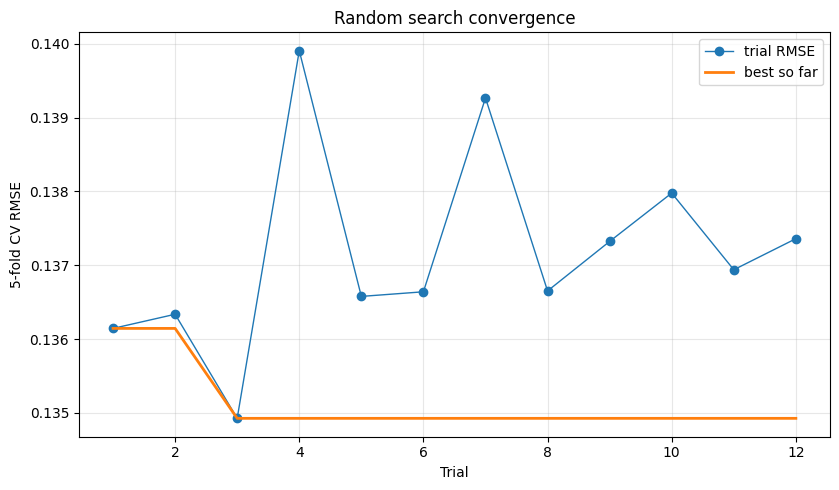

Best configuration found at trial 3 of 12.
If the best-so-far line flattened well before the last trial, the budget was already enough.


In [6]:
history = trial_table.sort_values("trial")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(history["trial"], history["cv_rmse"], marker="o", linewidth=1, label="trial RMSE")
ax.plot(history["trial"], history["cv_rmse"].cummin(), linewidth=2, label="best so far")
ax.set_xlabel("Trial")
ax.set_ylabel("5-fold CV RMSE")
ax.set_title("Random search convergence")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

best_trial_number = int(history.loc[history["cv_rmse"].idxmin(), "trial"])
print(f"Best configuration found at trial {best_trial_number} of {len(history)}.")
print("If the best-so-far line flattened well before the last trial, the budget was already enough.")

## 5. Final model

The winning configuration is refit on **all 53,574 training rows** — the folds only existed to choose it — then scored on Train and Test. The test rows were never used to pick a parameter.

In [7]:
RESULTS = []


def record(name, split, y_true, y_pred):
    row = {"Model": name, "Split": split,
           "MAE": mean_absolute_error(y_true, y_pred),
           "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
           "R2": r2_score(y_true, y_pred)}
    RESULTS.append(row)
    print(f"{name:24s} {split:5s} MAE={row['MAE']:.5f}  RMSE={row['RMSE']:.5f}  R2={row['R2']:.5f}")
    return row


T0 = time.time()
final_model = make_model(**best_params)
final_model.fit(X_train, y_train, **FIT_KWARGS)

record("Random Forest (tuned)", "Train", y_train, final_model.predict(X_train))
record("Random Forest (tuned)", "Test", y_test, final_model.predict(X_test))

cv_row = {"Model": "Random Forest (tuned)", "Split": f"CV{CV_FOLDS}-fold",
          "MAE": np.nan, "RMSE": cv_rmse, "R2": np.nan}
RESULTS.append(cv_row)
print(f"{'5-fold CV':24s} {'CV':5s} RMSE={cv_rmse:.5f}  (std {cv_std:.5f})")

results_df = pd.DataFrame(RESULTS)[["Model", "Split", "MAE", "RMSE", "R2"]]
display(results_df.round(5))

print(f"\nRefit on {len(X_train):,} rows in {(time.time() - T0) / 60:.1f} min")

Random Forest (tuned)    Train MAE=0.04304  RMSE=0.06155  R2=0.86874
Random Forest (tuned)    Test  MAE=0.09791  RMSE=0.13295  R2=0.37975
5-fold CV                CV    RMSE=0.13493  (std 0.00105)


,Model,Split,MAE,RMSE,R2
0,Random Forest (tuned),Train,0.04304,0.06155,0.86874
1,Random Forest (tuned),Test,0.09791,0.13295,0.37975
2,Random Forest (tuned),CV5-fold,NaN,0.13493,NaN



Refit on 53,574 rows in 1.3 min
Model saved to outputs\random_forest_tuning\models


## 6. Diagnostics

Which features the tuned model actually leans on, then how its errors behave on the test split.

Top 20 features:


,0
vegetarian_menu_ratio,0.0866
city,0.0791
log_menu_item_count,0.0324
locality_latitude,0.0322
average_cost_for_two,0.0297
locality_longitude,0.0283
cuisine,0.0244
menu_category_diversity,0.0204
school_nearest_distance_meters,0.0198
local_district_wealth_index,0.0198


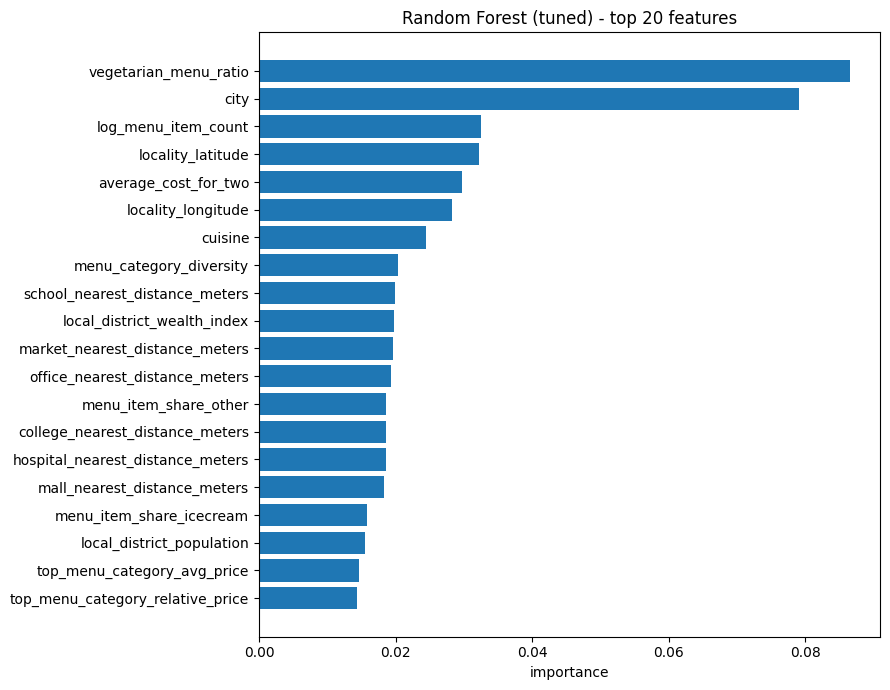

In [8]:
test_pred = final_model.predict(X_test)

if hasattr(final_model, "get_feature_importance"):
    importance_values = final_model.get_feature_importance()
elif hasattr(final_model, "feature_importances_"):
    importance_values = final_model.feature_importances_
else:
    importance_values = np.abs(final_model.coef_)

importance_series = pd.Series(importance_values, index=X_train.columns).sort_values(ascending=False)

print("Top 20 features:")
display(importance_series.head(20).to_frame().round(4))

fig, ax = plt.subplots(figsize=(9, 7))
top = importance_series.head(20)[::-1]
ax.barh(top.index, top.values)
ax.set_title("Random Forest (tuned) - top 20 features")
ax.set_xlabel("importance")
plt.tight_layout()
plt.show()
plt.close(fig)

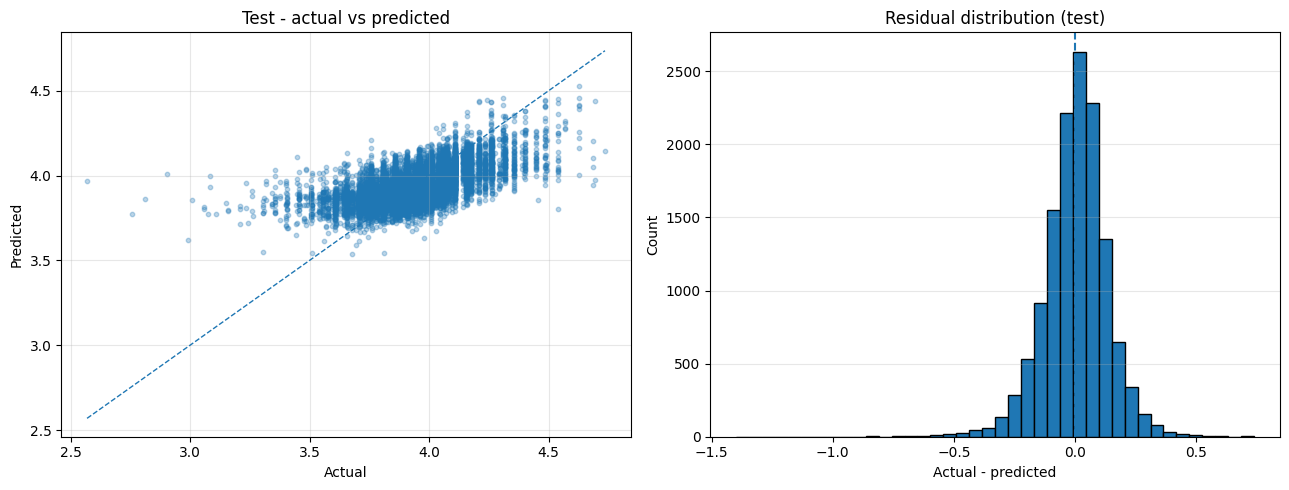

Mean residual : 0.00218
Residual std  : 0.13293


In [9]:
residuals = y_test.values - test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, test_pred, alpha=0.3, s=10)
lims = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
axes[0].plot(lims, lims, "--", linewidth=1)
axes[0].set_title("Test - actual vs predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].grid(alpha=0.3)

axes[1].hist(residuals, bins=40, edgecolor="black")
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Residual distribution (test)")
axes[1].set_xlabel("Actual - predicted")
axes[1].set_ylabel("Count")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

print(f"Mean residual : {residuals.mean():.5f}")
print(f"Residual std  : {residuals.std():.5f}")

## 7. Summary

Generated from the results above, so the wording can never disagree with the numbers.

In [10]:
REFERENCE = {"name": "Random Forest (main baseline, validation split)",
             "R2": 0.36157, "note": "100 trees, no tuning"}


def build_summary():
    test_row = results_df[results_df.Split == "Test"].iloc[0]
    delta = test_row.R2 - REFERENCE["R2"]
    out = ["### Result", "",
           f"- Best 5-fold CV RMSE: **{cv_rmse:.5f}** (fold standard deviation {cv_std:.5f}).",
           f"- Tuned model on test: MAE {test_row.MAE:.5f}, RMSE {test_row.RMSE:.5f}, R² {test_row.R2:.4f}.",
           f"- Main baseline reference: {REFERENCE['name']}, R² {REFERENCE['R2']:.4f} ({REFERENCE['note']}).",
           f"- Difference in R²: **{delta:+.4f}**.", "",
           "### Chosen parameters", "",
           "| Parameter | Value |", "|---|---|"]
    for key, value in best_params.items():
        out.append(f"| `{key}` | {value} |")

    out += ["", "### Honest reading", "",
            "- A single 5-fold estimate carries noise. Fold standard deviation is reported above; if it is "
            "larger than the improvement over the baseline, the tuning has not demonstrated anything.",
            "- The comparison against the main baseline is **not perfectly like-for-like**: that model was scored "
            "on the validation split, this one on the test split. Treat the difference as indicative.",
            "- Random search with a small trial budget finds a good configuration, not the optimum. "
            "Re-running with a different seed would land on different parameters with a very similar score — "
            "that is expected on a flat response surface, not a failure."]
    return "\n".join(out)


idisplay(Markdown(build_summary()))

### Result

- Best 5-fold CV RMSE: **0.13493** (fold standard deviation 0.00105).
- Tuned model on test: MAE 0.09791, RMSE 0.13295, R² 0.3797.
- Main baseline reference: Random Forest (main baseline, validation split), R² 0.3616 (100 trees, no tuning).
- Difference in R²: **+0.0182**.

### Chosen parameters

| Parameter | Value |
|---|---|
| `n_estimators` | 500 |
| `max_depth` | 31 |
| `min_samples_split` | 4 |
| `min_samples_leaf` | 2 |
| `max_features` | 0.7497988950401423 |

### Honest reading

- A single 5-fold estimate carries noise. Fold standard deviation is reported above; if it is larger than the improvement over the baseline, the tuning has not demonstrated anything.
- The comparison against the main baseline is **not perfectly like-for-like**: that model was scored on the validation split, this one on the test split. Treat the difference as indicative.
- Random search with a small trial budget finds a good configuration, not the optimum. Re-running with a different seed would land on different parameters with a very similar score — that is expected on a flat response surface, not a failure.
- If you later want a few thousandths more, add a Bayesian sampler or a finer local search around the best configuration. Neither is needed to justify the model as it stands.


Saved: outputs\random_forest_tuning\tables\summary.md


## 8. What this run found, in one place

**The model.** A Random Forest with 500 trees, depth 31, `min_samples_leaf` 2 and 75% of features offered per split.

**The score.** 5-fold CV RMSE 0.13493 (± 0.00105). On the untouched test split: MAE 0.09791, RMSE 0.13295, R² 0.37975. Against the untuned baseline (R² 0.36157) that is **+0.018** — real, but modest.

**The shape of the result.** Train R² is 0.86874 against test R² 0.37975. The model memorises the training rows and generalises far less. That gap is the single most important thing on this page: it says the ceiling is in the features, not the hyperparameters.

**What it leans on.** `vegetarian_menu_ratio` (0.087), `city` (0.079), then a long tail: menu item count, latitude/longitude, cost for two, cuisine. Menu and location do nearly all the work.

**What the search was worth.** The winning configuration appeared at trial 3 of 12. Trials 4-12 cost roughly 28 minutes and improved nothing. If you run this again, 5-6 trials is enough, or set `TIME_BUDGET_MIN`.

**Residuals.** Mean 0.00218, standard deviation 0.13293 — essentially unbiased, and wide relative to the target's own spread of 0.17.

## 9. Notes

- **No artifacts.** This notebook writes nothing: no CSV, no JSON, no figures, no model files. Every number and chart is inline, and the chosen parameters are stated in section 3.
- **The test split was never used for selection.** Every parameter came from 5-fold CV on the training rows.
- **Differences below about ±0.002 R² are noise** at this sample size. The fold standard deviation in section 3 is the yardstick.
- **`SAMPLE_ROWS`** runs the whole notebook on a subset for a quick check; results from it are not comparable to a full run.